# 23CSE301 Machine Learning Capstone — Regression Track
## Predicting banana `quality_score` from physical and agronomic measurements

**Dataset:** `data/raw/banana_quality_dataset.csv` (1,000 rows × 16 columns) · **Target:** `quality_score` (continuous)

| § | Content | Rubric |
|---|---|---|
| 1–2 | Problem statement and dataset description | — |
| 3–5 | Setup, loading, dataset audit, target and leakage audit | A1 |
| 6 | Exploratory data analysis with written observations | A2, A3 |
| 7 | Data cleaning: missing values, duplicates, outliers | B1 |
| 8–10 | Train/test split, feature engineering, leakage-safe preprocessing | B2, B3 |
| 11 | Training and tuning all ten regression algorithms | C1, C3 |
| 12–13 | Consolidated comparison table, tuning summary | C2, C3 |
| 14 | 5-fold cross-validated R² for the two best models | C2 |
| 15 | Model selection and diagnostic plots | C4 |
| 16 | Saving the model pipelines for the app | Bonus |
| 17–18 | Limitations and conclusion | — |

**Reproducibility:** `random_state = 42` everywhere; one 80:20 split shared by all ten models.

> **AI-assistance notice.** The code scaffolding in this notebook was produced with an AI assistant (Claude). Under guideline 7.5, analysis and interpretation must be the team's own: every cell marked ✍️ **DRAFT** contains observations read off the computed outputs and **must be verified and rewritten by the team before submission**.

## 1. Problem statement

Banana grading is usually done by hand. This notebook asks whether a fruit's measurable properties — ripeness index, sugar content (°Brix), firmness, size and weight, plus where and how it was grown — can predict its **continuous quality score**. A reliable model would let a packing line grade fruit automatically and explain *which* properties drive quality.

Formally: learn $f(\mathbf{x}) \approx$ `quality_score` from the input features, and compare the ten algorithms required by the guidelines on **R²**, **RMSE** and **MAE**, all on the same held-out test set.

## 2. Dataset description

| Column | Type | Meaning |
|---|---|---|
| `sample_id` | int | Row identifier |
| `variety`, `region` | categorical (8 levels each) | Banana cultivar and growing country |
| `quality_score` | float | **Target**: overall quality score |
| `quality_category` | categorical | Quality band derived from the score (checked for leakage in §5.1) |
| `ripeness_index`, `ripeness_category` | float / categorical | Ripeness measurement and its band |
| `sugar_content_brix` | float | Sugar content (°Brix) |
| `firmness_kgf` | float | Firmness (kg-force) |
| `length_cm`, `weight_g` | float | Size measurements |
| `harvest_date` | date string | Harvest day |
| `tree_age_years`, `altitude_m`, `rainfall_mm`, `soil_nitrogen_ppm` | float | Growing conditions |

**Source:** not documented in the files supplied with the assignment. Section 6 shows evidence that the data is synthetic.

## 3. Imports and configuration

In [1]:
import sys
from pathlib import Path

# Make the shared src/ package importable whether the notebook runs from notebooks/ or the repo root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import config
from src.data_loader import column_audit, load_banana
from src.evaluation import regression_metrics
from src.feature_engineering import add_banana_features
from src.model_training import cross_validate, kfold, load_pipeline, regression_specs, run_model, save_pipeline
from src.preprocessing import make_regression_pipeline, regression_xy, train_test
from src.utils import load_json, save_json, slugify
from src.visualization import (plot_feature_importance, plot_metric_bars, plot_predicted_vs_actual,
                               plot_residuals, save_fig, set_plot_style)

set_plot_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
TRACK = "regression"

print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__, "| numpy:", np.__version__)
print("RANDOM_STATE:", RANDOM_STATE)

Python      : 3.13.9
scikit-learn: 1.7.2 | pandas: 2.3.3 | numpy: 2.3.5
RANDOM_STATE: 42


## 4. Loading the data

In [2]:
df = load_banana()
print(f"Loaded {config.DATASET_FILES['banana'].name}: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Loaded banana_quality_dataset.csv: 1000 rows x 16 columns


,sample_id,variety,region,quality_score,quality_category,ripeness_index,ripeness_category,sugar_content_brix,firmness_kgf,length_cm,weight_g,harvest_date,tree_age_years,altitude_m,rainfall_mm,soil_nitrogen_ppm
0,1,Manzano,Colombia,1.88,Processing,2.11,Turning,16.83,3.53,21.44,146.92,2023-10-16,13.7,58.2,2440.5,183.6
1,2,Plantain,Guatemala,2.42,Processing,4.25,Ripe,16.73,4.09,26.11,160.48,2023-10-14,5.1,280.2,2374.6,109.8
2,3,Burro,Ecuador,3.57,Premium,6.24,Overripe,21.34,1.63,25.20,225.27,2023-09-08,17.7,1246.9,1191.5,147.7
3,4,Manzano,Ecuador,2.21,Processing,5.39,Ripe,16.75,3.31,13.08,137.80,2023-10-07,13.0,1150.2,2845.1,92.8
4,5,Red Dacca,Ecuador,2.35,Processing,5.84,Ripe,16.90,3.07,12.98,227.84,2023-10-02,4.8,526.0,2136.9,129.7


## 5. Dataset audit (A1)

Shape, data types, missing values, cardinality, duplicates and descriptive statistics.

In [3]:
audit = column_audit(df)
display(audit)
print("Total missing cells            :", int(df.isna().sum().sum()))
print("Sentinel-coded cells ('?', 'NA'):", int(audit["sentinel_coded"].sum()))
print("Duplicate rows                 :", int(df.duplicated().sum()))
print("Duplicates ignoring sample_id  :", int(df.drop(columns="sample_id").duplicated().sum()))
print("Memory usage                   :", round(df.memory_usage(deep=True).sum() / 1024, 1), "KB")

,column,dtype,kind,missing,missing_pct,sentinel_coded,n_unique,unique_pct,constant,identifier_like,example
0,sample_id,int64,numeric,0,0.0,0,1000,100.0,False,True,1
1,variety,object,categorical/text,0,0.0,0,8,0.8,False,False,Manzano
2,region,object,categorical/text,0,0.0,0,8,0.8,False,False,Colombia
3,quality_score,float64,numeric,0,0.0,0,234,23.4,False,False,1.88
4,quality_category,object,categorical/text,0,0.0,0,4,0.4,False,False,Processing
5,ripeness_index,float64,numeric,0,0.0,0,481,48.1,False,False,2.11
6,ripeness_category,object,categorical/text,0,0.0,0,4,0.4,False,False,Turning
7,sugar_content_brix,float64,numeric,0,0.0,0,540,54.0,False,False,16.83
8,firmness_kgf,float64,numeric,0,0.0,0,401,40.1,False,False,3.53
9,length_cm,float64,numeric,0,0.0,0,790,79.0,False,False,21.44


Total missing cells            : 0
Sentinel-coded cells ('?', 'NA'): 0
Duplicate rows                 : 0
Duplicates ignoring sample_id  : 0
Memory usage                   : 363.1 KB


In [4]:
display(df.describe().T.round(3))
for col in ["variety", "region", "quality_category", "ripeness_category"]:
    print(f"{col}: " + ", ".join(f"{k}={v}" for k, v in df[col].value_counts().items()))
print(f"harvest_date: {df['harvest_date'].nunique()} distinct days, {df['harvest_date'].min()} to {df['harvest_date'].max()}")

,count,mean,std,min,25%,50%,75%,max
sample_id,1000.0,500.500,288.819,1.00,250.750,500.500,750.250,1000.00
quality_score,1000.0,2.465,0.541,0.92,2.090,2.440,2.850,3.89
ripeness_index,1000.0,4.042,1.753,1.02,2.448,4.110,5.562,7.00
sugar_content_brix,1000.0,18.517,2.035,15.00,16.828,18.500,20.312,21.98
firmness_kgf,1000.0,2.707,1.289,0.50,1.590,2.680,3.820,5.00
length_cm,1000.0,19.882,5.736,10.00,14.902,19.890,24.800,29.95
weight_g,1000.0,164.739,49.163,81.05,122.398,163.365,205.775,249.89
tree_age_years,1000.0,10.880,5.216,2.00,6.300,10.700,15.600,20.00
altitude_m,1000.0,723.557,427.373,0.40,353.950,726.000,1071.725,1498.40
rainfall_mm,1000.0,1972.993,564.468,1000.50,1498.750,1957.400,2431.800,2992.00


variety: Plantain=146, Fehi=134, Cavendish=133, Burro=125, Manzano=119, Lady Finger=117, Red Dacca=113, Blue Java=113
region: Ecuador=137, Colombia=136, India=133, Costa Rica=130, Philippines=127, Guatemala=126, Honduras=107, Brazil=104
quality_category: Processing=506, Good=434, Unripe=35, Premium=25
ripeness_category: Ripe=349, Turning=310, Green=174, Overripe=167
harvest_date: 61 distinct days, 2023-09-01 to 2023-10-31


### Observation — audit
- 1,000 rows × 16 columns; **0 missing cells**, no sentinel codes, **0 duplicate rows** (also 0 when `sample_id` is ignored).
- `sample_id` is unique for every row, so it is an identifier with no predictive meaning.
- Every numeric range is physically plausible (for example length 10–29.95 cm, weight 81–250 g, firmness 0.5–5.0 kgf); nothing is negative or impossible.
- `variety` and `region` have 8 roughly balanced levels each; `harvest_date` covers one 61-day season.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 5.1 Target selection and target-leakage audit

`quality_score` is continuous, so it is the regression target. Before trusting it we check whether any other column is *derived from* it. Such a column would be **target leakage**: it would hand the model the answer and produce a fake, near-perfect score.

In [5]:
quality_bins = (df.groupby("quality_category")["quality_score"]
                  .agg(min_score="min", max_score="max", n="count").sort_values("min_score"))
ripeness_bins = (df.groupby("ripeness_category")["ripeness_index"]
                   .agg(min_index="min", max_index="max", n="count").sort_values("min_index"))
display(quality_bins)
display(ripeness_bins)

days = (pd.to_datetime(df["harvest_date"]) - pd.to_datetime(df["harvest_date"]).min()).dt.days
print(f"Correlation of harvest day-of-season with quality_score: {np.corrcoef(days, df['quality_score'])[0, 1]:+.4f}")

,min_score,max_score,n
quality_category,,,
Unripe,0.92,1.50,35
Processing,1.51,2.50,506
Good,2.51,3.50,434
Premium,3.51,3.89,25


,min_index,max_index,n
ripeness_category,,,
Green,1.02,2.00,174
Turning,2.01,3.99,310
Ripe,4.02,5.99,349
Overripe,6.02,7.00,167


Correlation of harvest day-of-season with quality_score: -0.0128


### Observation — leakage audit
- The four `quality_category` ranges are contiguous and do not overlap (cut points 1.50 / 2.50 / 3.50). **`quality_category` is a binned copy of the target**, so using it as a feature would be target leakage. It is excluded.
- `ripeness_category` is a binned copy of `ripeness_index` (cut points ≈ 2 / 4 / 6). It is not leakage, but it adds nothing that `ripeness_index` does not already provide, so it is dropped as redundant.
- `harvest_date` spans a single season, and its day index has almost zero correlation with quality (−0.013), so it is dropped.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

In [6]:
print("Target              :", config.REG_TARGET)
print("Numeric features    :", config.REG_NUMERIC)
print("Categorical features:", config.REG_CATEGORICAL)
print("Excluded columns:")
for col, reason in config.REG_DROPPED.items():
    print(f"  - {col:18s} {reason}")

Target              : quality_score
Numeric features    : ['ripeness_index', 'sugar_content_brix', 'firmness_kgf', 'length_cm', 'weight_g', 'tree_age_years', 'altitude_m', 'rainfall_mm', 'soil_nitrogen_ppm']
Categorical features: ['variety', 'region']
Excluded columns:
  - sample_id          row identifier with no predictive content
  - quality_category   TARGET LEAKAGE: an exact binning of quality_score
  - ripeness_category  coarser duplicate of ripeness_index
  - harvest_date       single 61-day season; no measurable relationship with the target


## 6. Exploratory data analysis (A2, A3)
### 6.1 Target distribution

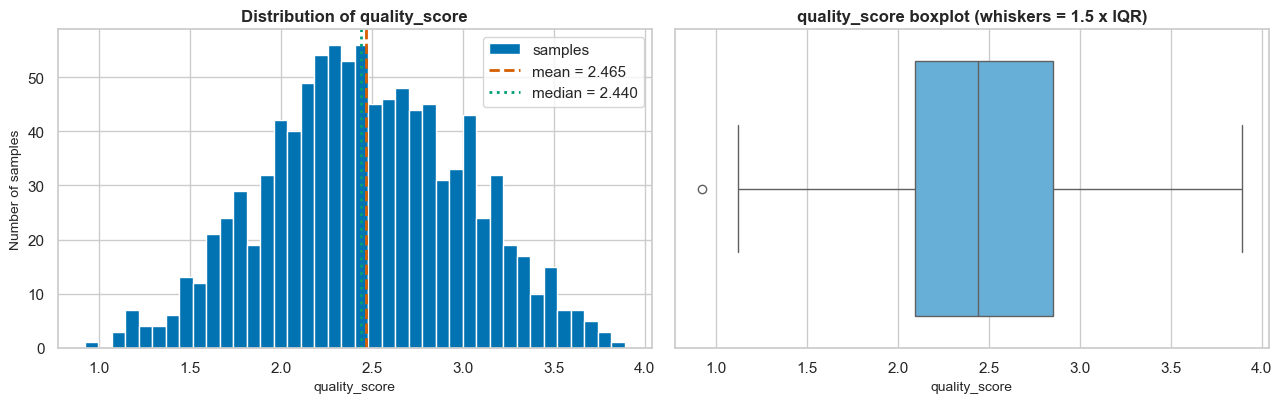

skewness = 0.010, kurtosis = -0.398


In [7]:
target = df[config.REG_TARGET]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(target, bins=40, color=sns.color_palette()[0], edgecolor="white", label="samples")
axes[0].axvline(target.mean(), color=sns.color_palette()[3], linestyle="--", linewidth=2, label=f"mean = {target.mean():.3f}")
axes[0].axvline(target.median(), color=sns.color_palette()[2], linestyle=":", linewidth=2, label=f"median = {target.median():.3f}")
axes[0].set(title="Distribution of quality_score", xlabel="quality_score", ylabel="Number of samples")
axes[0].legend()
sns.boxplot(x=target, ax=axes[1], color=sns.color_palette()[9])
axes[1].set(title="quality_score boxplot (whiskers = 1.5 x IQR)", xlabel="quality_score", ylabel="")
fig.tight_layout(); save_fig(fig, TRACK, "eda_target_distribution"); plt.show()
print(f"skewness = {target.skew():.3f}, kurtosis = {target.kurt():.3f}")

### Observation — target distribution
`quality_score` ranges from 0.92 to 3.89. Its mean (2.465) and median (2.44) almost coincide and its skewness is 0.010, so the target is **symmetric**: no log transform is needed, and squared-error metrics will not be dominated by a long tail. The boxplot marks a single low point, which is examined in §7.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.2 Distribution of every numerical feature

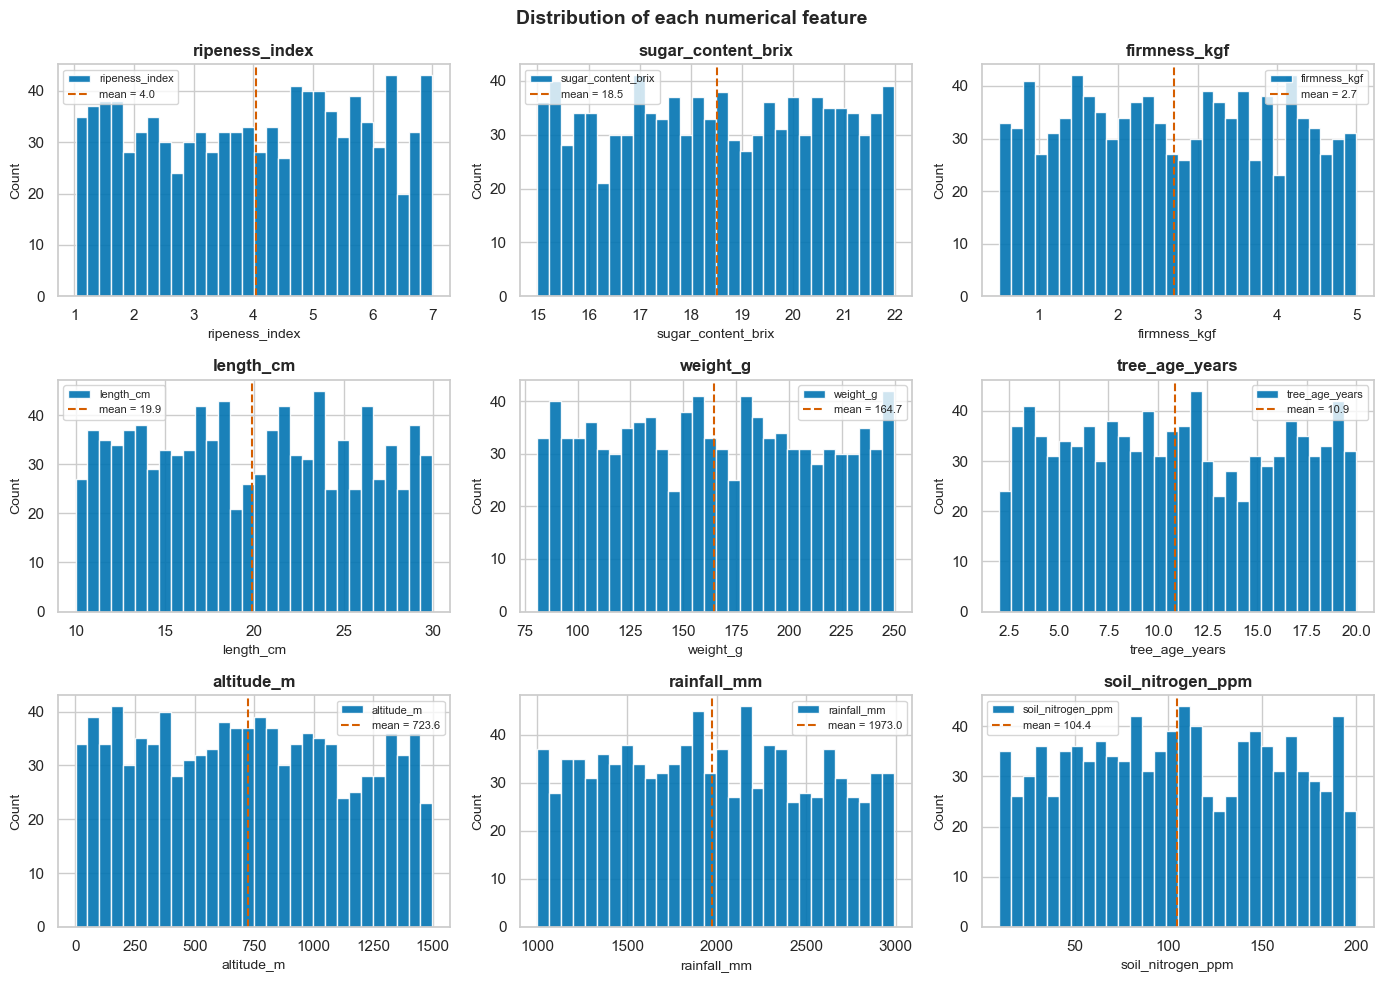

,min,max,mean,std,skew
ripeness_index,1.02,7.00,4.042,1.753,-0.059
sugar_content_brix,15.00,21.98,18.517,2.035,-0.022
firmness_kgf,0.50,5.00,2.707,1.289,0.031
length_cm,10.00,29.95,19.882,5.736,0.032
weight_g,81.05,249.89,164.739,49.163,0.032
tree_age_years,2.00,20.00,10.880,5.216,0.060
altitude_m,0.40,1498.40,723.557,427.373,0.064
rainfall_mm,1000.50,2992.00,1972.993,564.468,0.057
soil_nitrogen_ppm,10.00,199.90,104.391,53.608,0.014


In [8]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), config.REG_NUMERIC):
    ax.hist(df[col], bins=30, color=sns.color_palette()[0], edgecolor="white", alpha=0.9, label=col)
    ax.axvline(df[col].mean(), color=sns.color_palette()[3], linestyle="--", label=f"mean = {df[col].mean():.1f}")
    ax.set(title=col, xlabel=col, ylabel="Count")
    ax.legend(fontsize=8)
fig.suptitle("Distribution of each numerical feature", fontsize=14, fontweight="bold")
fig.tight_layout(); save_fig(fig, TRACK, "eda_numeric_distributions"); plt.show()
display(df[config.REG_NUMERIC].agg(["min", "max", "mean", "std", "skew"]).T.round(3))

### Observation — numerical distributions
All nine features are close to **uniform** rather than bell-shaped (every |skew| < 0.07) and fill their ranges evenly between round-number bounds (for example firmness exactly 0.50–5.00). That pattern is typical of synthetic or tightly designed data. The feature scales differ enormously (rainfall's standard deviation is about 440× firmness's), so distance-based, margin-based and penalised models need **standardisation**.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.3 Distribution of the categorical features

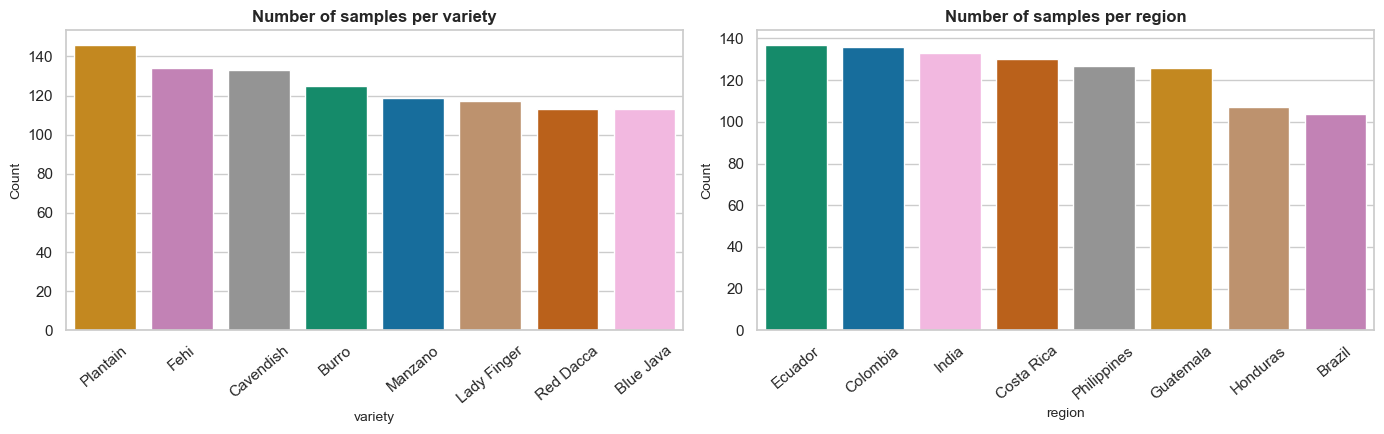

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, config.REG_CATEGORICAL):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, hue=col, palette="colorblind", legend=False)
    ax.set(title=f"Number of samples per {col}", xlabel=col, ylabel="Count")
    ax.tick_params(axis="x", rotation=40)
fig.tight_layout(); save_fig(fig, TRACK, "eda_categorical_distributions"); plt.show()

### Observation — categorical distributions
Both nominal features are fairly balanced. The largest level has 146 rows (`Plantain`) and the smallest 104 (`Brazil`), so no one-hot column will be nearly empty.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.4 Correlation heatmap

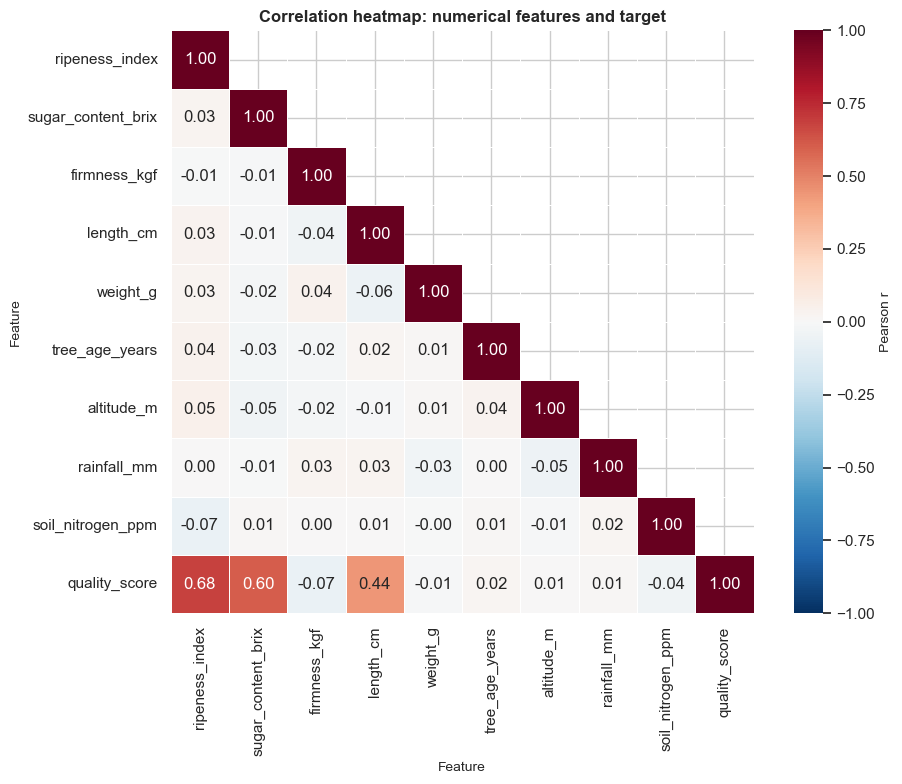

Correlation with quality_score:
ripeness_index        0.6798
sugar_content_brix    0.6028
length_cm             0.4392
firmness_kgf         -0.0679
soil_nitrogen_ppm    -0.0394
tree_age_years        0.0222
weight_g             -0.0146
rainfall_mm           0.0114
altitude_m            0.0052
Largest |r| between two different features: 0.065


In [10]:
corr = df[config.REG_NUMERIC + [config.REG_TARGET]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set(title="Correlation heatmap: numerical features and target", xlabel="Feature", ylabel="Feature")
fig.tight_layout(); save_fig(fig, TRACK, "eda_correlation_heatmap"); plt.show()
target_corr = corr[config.REG_TARGET].drop(config.REG_TARGET).sort_values(key=abs, ascending=False)
off_diag = corr.drop(index=config.REG_TARGET, columns=config.REG_TARGET).where(~np.eye(len(config.REG_NUMERIC), dtype=bool))
print("Correlation with quality_score:"); print(target_corr.round(4).to_string())
print(f"Largest |r| between two different features: {off_diag.abs().max().max():.3f}")

### Observation — correlations
Only three features have a clear linear relationship with the target: `ripeness_index` (r = +0.68), `sugar_content_brix` (+0.60) and `length_cm` (+0.44). The growing-condition features and `weight_g` have |r| ≤ 0.04. Between features, no pair exceeds |r| ≈ 0.07, so there is **essentially no multicollinearity**, and we should not expect Ridge or Lasso to beat plain least squares by much. `firmness_kgf` has r ≈ −0.07, but Pearson's r only measures *linear* association; §6.5 shows why that number is misleading here.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.5 Feature–target scatter plots

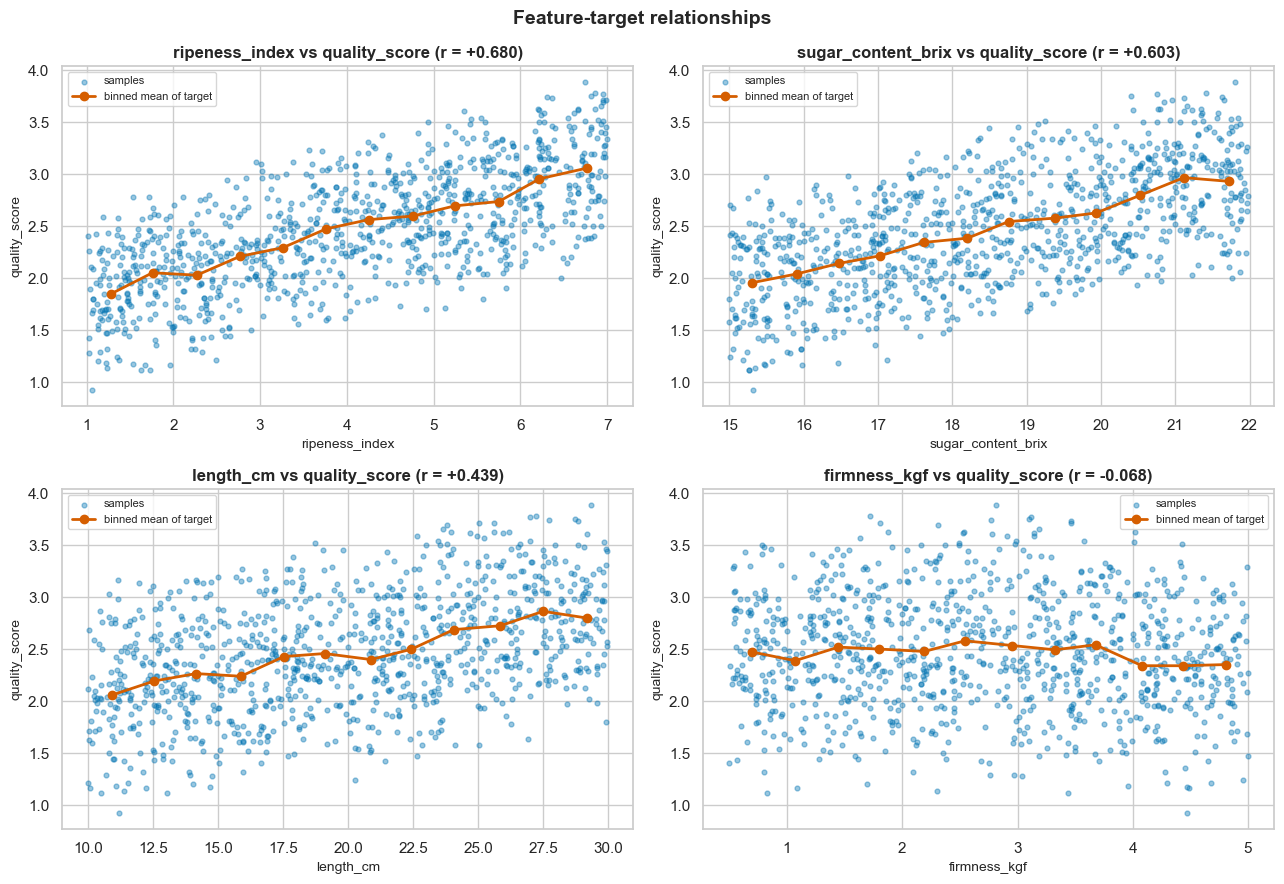

In [11]:
scatter_features = ["ripeness_index", "sugar_content_brix", "length_cm", "firmness_kgf"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), scatter_features):
    ax.scatter(df[col], target, s=12, alpha=0.4, color=sns.color_palette()[0], label="samples")
    binned = df.groupby(pd.cut(df[col], bins=12), observed=True).agg(x=(col, "mean"), y=(config.REG_TARGET, "mean"))
    ax.plot(binned["x"], binned["y"], color=sns.color_palette()[3], marker="o", linewidth=2, label="binned mean of target")
    ax.set(title=f"{col} vs quality_score (r = {np.corrcoef(df[col], target)[0, 1]:+.3f})", xlabel=col, ylabel="quality_score")
    ax.legend(fontsize=8)
fig.suptitle("Feature-target relationships", fontsize=14, fontweight="bold")
fig.tight_layout(); save_fig(fig, TRACK, "eda_feature_target_scatter"); plt.show()

### Observation — scatter plots
- `ripeness_index`, `sugar_content_brix` and `length_cm` show upward bands whose binned means are close to straight lines, i.e. roughly linear effects.
- `firmness_kgf` looks like a shapeless cloud (r = −0.07). Its binned mean shows only a **faint hump**: about 2.40 at 1 kgf, 2.57 near 2.5 kgf, and 2.35 above 4 kgf. A rising half and a falling half would cancel in Pearson's r, so this is worth testing properly. §9 does that after controlling for the other features.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.6 Target by categorical feature

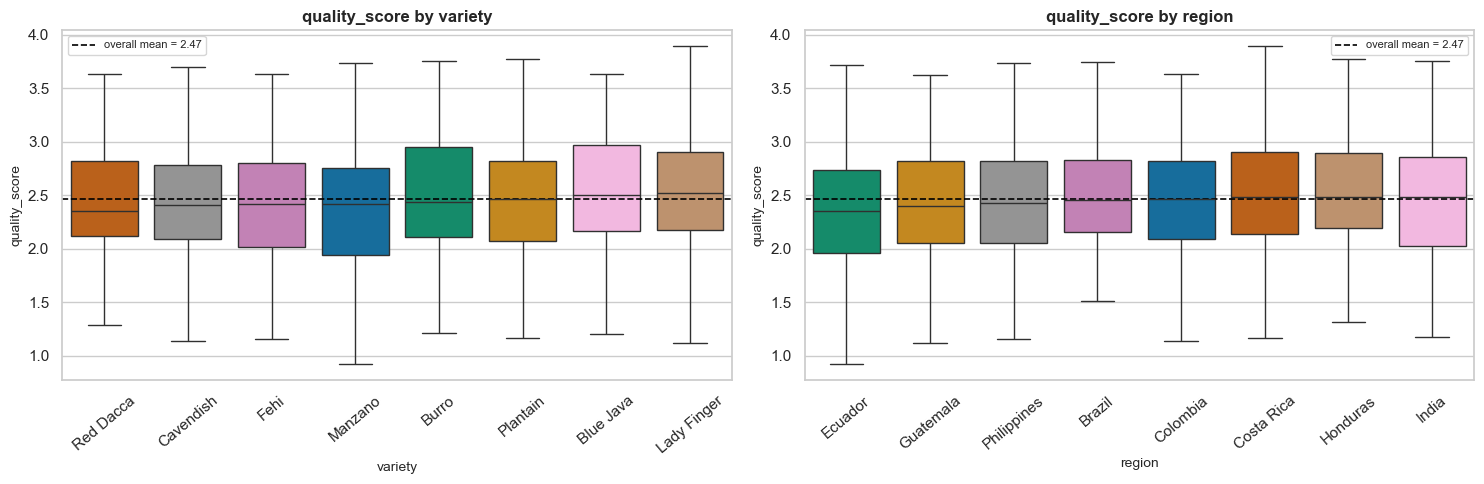

variety: spread of group means = 0.143 (overall target std = 0.541)
region: spread of group means = 0.129 (overall target std = 0.541)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, config.REG_CATEGORICAL):
    order = df.groupby(col)[config.REG_TARGET].median().sort_values().index
    sns.boxplot(data=df, x=col, y=config.REG_TARGET, order=order, ax=ax, hue=col, palette="colorblind", legend=False)
    ax.axhline(target.mean(), color="black", linestyle="--", linewidth=1.2, label=f"overall mean = {target.mean():.2f}")
    ax.set(title=f"quality_score by {col}", xlabel=col, ylabel="quality_score")
    ax.tick_params(axis="x", rotation=40); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, TRACK, "eda_target_by_category"); plt.show()
for col in config.REG_CATEGORICAL:
    means = df.groupby(col)[config.REG_TARGET].mean()
    print(f"{col}: spread of group means = {means.max() - means.min():.3f} (overall target std = {target.std():.3f})")

### Observation — categorical effects
Every variety and region box straddles the overall mean. The spread between group means is only about a quarter of the target's standard deviation, so `variety` and `region` probably carry little signal. They are still kept, so the models can use any small effect that does exist.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 7. Data cleaning (B1)
### 7.1 Missing values and duplicates
The audit already showed **0 missing cells** and **0 duplicates**, so nothing needs to be imputed or removed. A median / most-frequent `SimpleImputer` is still placed *inside* the pipeline. It is a no-op on this training data, but it protects the deployed app if an input ever arrives incomplete, and because it lives in the pipeline it is fitted on training data only.

### 7.2 Outlier analysis

,IQR outliers (1.5 x IQR),|z| > 3
ripeness_index,0,0
sugar_content_brix,0,0
firmness_kgf,0,0
length_cm,0,0
weight_g,0,0
tree_age_years,0,0
altitude_m,0,0
rainfall_mm,0,0
soil_nitrogen_ppm,0,0
quality_score,1,0


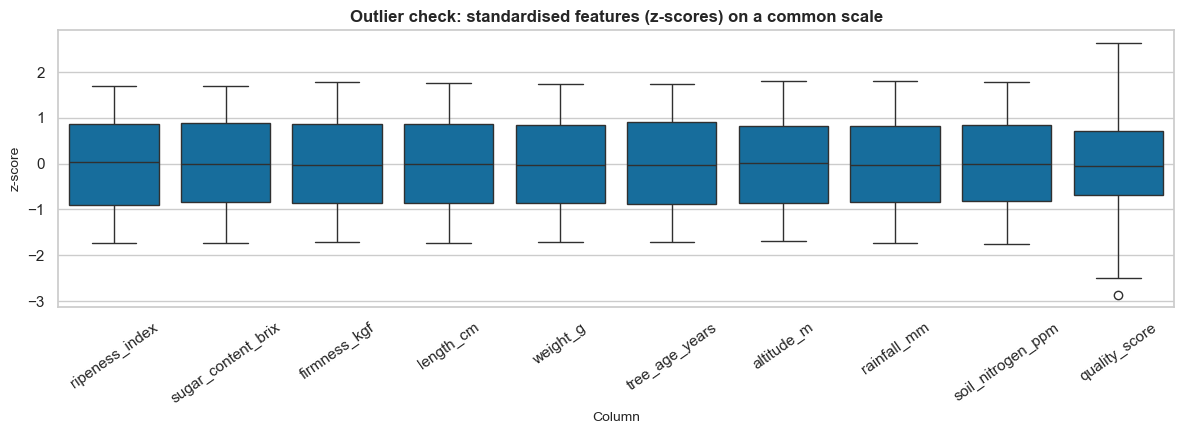

,sample_id,quality_score,ripeness_index,sugar_content_brix,firmness_kgf,length_cm,quality_category
283,284,0.92,1.06,15.32,4.47,11.17,Unripe


In [13]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))).sum())

outliers = pd.DataFrame({
    "IQR outliers (1.5 x IQR)": {c: iqr_outliers(df[c]) for c in config.REG_NUMERIC + [config.REG_TARGET]},
    "|z| > 3": {c: int((np.abs((df[c] - df[c].mean()) / df[c].std()) > 3).sum()) for c in config.REG_NUMERIC + [config.REG_TARGET]},
})
display(outliers)

z = (df[config.REG_NUMERIC + [config.REG_TARGET]] - df[config.REG_NUMERIC + [config.REG_TARGET]].mean()) / df[config.REG_NUMERIC + [config.REG_TARGET]].std()
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=z, ax=ax, color=sns.color_palette()[0])
ax.set(title="Outlier check: standardised features (z-scores) on a common scale", xlabel="Column", ylabel="z-score")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout(); save_fig(fig, TRACK, "eda_outlier_boxplots"); plt.show()

q1, q3 = target.quantile([0.25, 0.75])
display(df[(target < q1 - 1.5 * (q3 - q1)) | (target > q3 + 1.5 * (q3 - q1))][
    ["sample_id", "quality_score", "ripeness_index", "sugar_content_brix", "firmness_kgf", "length_cm", "quality_category"]])

### Decision — outliers: checked and retained
The nine predictors have **no** IQR or |z| > 3 outliers. The single flagged value is a target of 0.92 (sample 284). It is retained because (1) it lies inside the dataset's own `Unripe` band, (2) its inputs explain it, with ripeness, sugar and length all near their minimums, and (3) deleting the lowest scores would teach the model that poor fruit does not exist. No rows are removed, so the cleaned dataset is the full 1,000 rows.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 8. Train/test split (B2)

The split happens **before** anything is fitted. One 80:20 split with `random_state=42` is shared by all ten models, so their test scores are directly comparable. Leakage, identifier and redundant columns are removed here and never enter `X`.

In [14]:
X, y = regression_xy(df)
X_train, X_test, y_train, y_test = train_test(X, y)
print(f"X_train {X_train.shape} | X_test {X_test.shape} | split {len(X_train) / len(X):.0%}/{len(X_test) / len(X):.0%}")
display(pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(3))

X_train (800, 11) | X_test (200, 11) | split 80%/20%


,train,test
count,800.000,200.000
mean,2.474,2.429
std,0.539,0.550
min,0.920,1.160
25%,2.118,2.010
50%,2.440,2.415
75%,2.850,2.812
max,3.890,3.770


**Note on stratification.** Rubric item B2 mentions a *stratified* split. Stratification is defined for class labels, and `quality_score` is continuous, so the classification notebook is where `stratify=y` applies. The table above shows the plain random split already gives train and test sets with closely matching target means, spreads and quartiles.

## 9. Feature engineering (B3)

§6.5 suggested an inverted-U effect of firmness. Here we confirm it **using training data only**: fit a linear model, then plot its *training residuals* against firmness. If the linear form is right, the residuals should scatter randomly around zero.

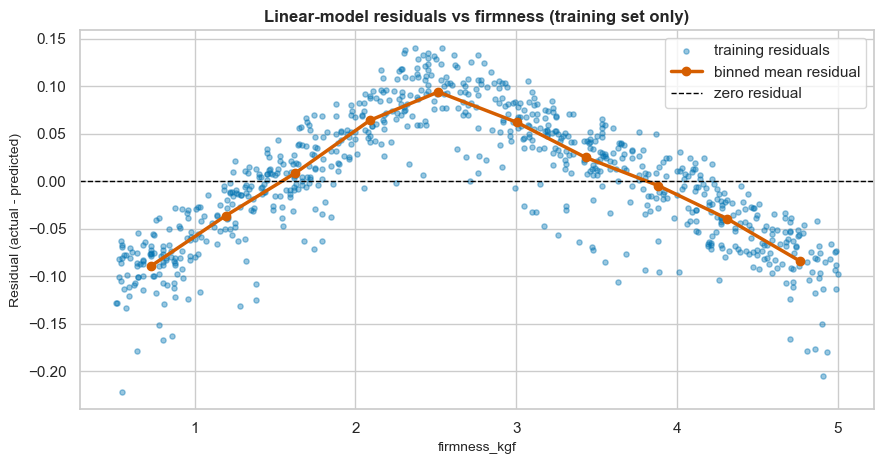

     x       y
0.7310 -0.0888
1.1929 -0.0362
1.6251  0.0087
2.0905  0.0644
2.5147  0.0942
3.0028  0.0622
3.4311  0.0252
3.8812 -0.0043
4.3114 -0.0394
4.7660 -0.0841


In [15]:
base_pre = ColumnTransformer([("num", StandardScaler(), config.REG_NUMERIC),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), config.REG_CATEGORICAL)])
diag = Pipeline([("pre", base_pre), ("model", LinearRegression())]).fit(X_train, y_train)
residuals = y_train - diag.predict(X_train)
binned = (pd.DataFrame({"f": X_train["firmness_kgf"], "r": residuals})
            .groupby(pd.cut(X_train["firmness_kgf"], bins=10), observed=True).agg(x=("f", "mean"), y=("r", "mean")))
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(X_train["firmness_kgf"], residuals, s=14, alpha=0.4, color=sns.color_palette()[0], label="training residuals")
ax.plot(binned["x"], binned["y"], color=sns.color_palette()[3], marker="o", linewidth=2.5, label="binned mean residual")
ax.axhline(0, color="black", linestyle="--", linewidth=1, label="zero residual")
ax.set(title="Linear-model residuals vs firmness (training set only)", xlabel="firmness_kgf", ylabel="Residual (actual - predicted)")
ax.legend(); fig.tight_layout(); save_fig(fig, TRACK, "fe_firmness_residual_diagnostic"); plt.show()
print(binned.round(4).to_string(index=False))

In [16]:
def cv_r2_with_extra(extra=None):
    """5-fold CV R2 of a linear pipeline on the TRAINING set, optionally with one extra feature."""
    frame, numeric = X_train.copy(), list(config.REG_NUMERIC)
    if extra is not None:
        frame[extra[0]] = extra[1](frame)
        numeric.append(extra[0])
    pre = ColumnTransformer([("num", StandardScaler(), numeric),
                             ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), config.REG_CATEGORICAL)])
    s = cross_val_score(Pipeline([("pre", pre), ("model", LinearRegression())]), frame, y_train, cv=kfold(), scoring="r2")
    return s.mean(), s.std()

candidates = {
    "(none - baseline)": None,
    "firmness_squared = firmness^2": ("firmness_squared", lambda d: d["firmness_kgf"] ** 2),
    "sugar_firmness_ratio = brix / firmness": ("sugar_firmness_ratio", lambda d: d["sugar_content_brix"] / d["firmness_kgf"]),
    "fruit_density = weight / length": ("fruit_density", lambda d: d["weight_g"] / d["length_cm"]),
}
fe = pd.DataFrame([(name, *cv_r2_with_extra(spec)) for name, spec in candidates.items()],
                  columns=["candidate feature", "CV R2 mean", "CV R2 std"])
fe["gain vs baseline"] = fe["CV R2 mean"] - fe.loc[0, "CV R2 mean"]
display(fe.round(5))

,candidate feature,CV R2 mean,CV R2 std,gain vs baseline
0,(none - baseline),0.98320,0.00160,0.00000
1,firmness_squared = firmness^2,0.99582,0.00044,0.01262
2,sugar_firmness_ratio = brix / firmness,0.99163,0.00092,0.00843
3,fruit_density = weight / length,0.98307,0.00152,-0.00013


### Feature-engineering decision
- **Accepted: `firmness_squared = firmness_kgf²`.** The training residuals form a smooth inverted parabola. The linear model under-predicts mid-range firmness and over-predicts at both extremes, which is a systematic misspecification that a squared term corrects. In 5-fold CV on the training set it gives the largest gain of the three candidates and also lowers the fold-to-fold spread. Domain reading: fruit that is too soft is overripe and fruit that is too hard is unripe, so quality peaks in between.
- **Rejected:** `sugar_firmness_ratio` (a smaller gain) and `fruit_density` (no gain).
- **No leakage risk.** The feature is row-wise arithmetic on one column: it uses no target values and no statistics computed across rows. It is implemented in `src/feature_engineering.add_banana_features` and runs as the **first step of every saved pipeline**, so the app computes it identically.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 10. The leakage-safe preprocessing pipeline

Every model is wrapped in the same `Pipeline`:

1. `features`: `FunctionTransformer(add_banana_features)` adds `firmness_squared` (row-wise, nothing learned).
2. `preprocess`: a `ColumnTransformer` with
   - numeric: median `SimpleImputer` → `StandardScaler` (plus `PolynomialFeatures` for the polynomial model only)
   - categorical: most-frequent `SimpleImputer` → `OneHotEncoder(drop="first", handle_unknown="ignore")`. Variety and region are **nominal** (no order), so one-hot encoding is used rather than label encoding.
3. `model`: the estimator.

Calling `pipeline.fit(X_train, y_train)` fits the imputers, encoder and scaler on the **training rows only**. The check below proves it: the fitted scaler's means equal the training-set means, not the full-dataset means.

In [17]:
demo = make_regression_pipeline(LinearRegression()).fit(X_train, y_train)
display(demo)
scaler = demo.named_steps["preprocess"].named_transformers_["num"].named_steps["scale"]
num_cols = config.REG_NUMERIC + config.REG_ENGINEERED
print("Scaler means == TRAIN means:", np.allclose(scaler.mean_, add_banana_features(X_train)[num_cols].mean()))
print("Scaler means == FULL-data means:", np.allclose(scaler.mean_, add_banana_features(X)[num_cols].mean()))
feature_names = demo.named_steps["preprocess"].get_feature_names_out()
print(f"Design matrix: {len(feature_names)} columns ->", list(feature_names))

,steps,"[('features', ...), ('preprocess', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...001A38E05DE40>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,None


Scaler means == TRAIN means: True
Scaler means == FULL-data means: False
Design matrix: 24 columns -> ['num__ripeness_index', 'num__sugar_content_brix', 'num__firmness_kgf', 'num__length_cm', 'num__weight_g', 'num__tree_age_years', 'num__altitude_m', 'num__rainfall_mm', 'num__soil_nitrogen_ppm', 'num__firmness_squared', 'cat__variety_Burro', 'cat__variety_Cavendish', 'cat__variety_Fehi', 'cat__variety_Lady Finger', 'cat__variety_Manzano', 'cat__variety_Plantain', 'cat__variety_Red Dacca', 'cat__region_Colombia', 'cat__region_Costa Rica', 'cat__region_Ecuador', 'cat__region_Guatemala', 'cat__region_Honduras', 'cat__region_India', 'cat__region_Philippines']


## 11. Training and tuning the ten regression algorithms (C1, C3)

**Protocol, identical for every model** (`src/model_training.run_model`):
1. Fit a **baseline** (library defaults or a documented starting value) on the training set and score it on the test set.
2. **Tune** with `GridSearchCV` (or `RandomizedSearchCV` for the larger forest and boosting grids) using **5-fold CV on the training set only**, scoring R².
3. Score the tuned best estimator on the same test set. The test set never influences any choice.

Each model's search space is defined in `regression_specs()`, listed below.

In [18]:
specs = {s.name: s for s in regression_specs()}
display(pd.DataFrame([{"model": s.name, "search": s.search if s.param_grid else "none",
                       "baseline": s.baseline_note,
                       "grid": {k.split("__")[-1]: v for k, v in s.param_grid.items()}} for s in specs.values()]))

runs = {}

def reg_metric(model, X_, y_):
    return regression_metrics(y_, model.predict(X_))

def train(name):
    r = run_model(specs[name], X_train, y_train, X_test, y_test, reg_metric, kfold(), "r2")
    runs[name] = r
    rows = {"baseline (test)": r["baseline_test"]}
    if r["search"] is not None:
        rows["tuned (test)"] = r["tuned_test"]
        print(f"Best parameters (5-fold CV on train): {r['best_params']} | best CV R2 = {r['best_cv_score']:.5f}")
    rows["final model (train)"] = r["final_train"]
    display(pd.DataFrame(rows).T.round(5))
    return r

def cv_table(r, top=8):
    """Top configurations from a search, ranked by mean CV R2."""
    res = pd.DataFrame(r["search"].cv_results_)
    cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
    out = res.sort_values("rank_test_score")[cols].head(top)
    out.columns = [c.replace("param_", "").split("__")[-1] for c in out.columns]
    return out

,model,search,baseline,grid
0,Linear Regression,none,"ordinary least squares, no hyperparameters to tune",{}
1,Ridge Regression,grid,library defaults,"{'alpha': [0.001, 0.0031622776601683794, 0.01, 0.03162277660168379, 0.1, 0.3..."
2,Lasso Regression,grid,library defaults,"{'alpha': [1e-05, 0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]}"
3,ElasticNet Regression,grid,library defaults,"{'alpha': [0.0001, 0.001, 0.01, 0.1], 'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}"
4,Polynomial Regression,grid,degree=2 on the numeric block,"{'degree': [1, 2, 3]}"
5,Decision Tree Regressor,grid,library defaults,"{'max_depth': [3, 5, 7, 9, 12, None], 'min_samples_leaf': [1, 5, 10, 20]}"
6,Random Forest Regressor,random,library defaults,"{'n_estimators': [100, 200, 400], 'max_depth': [None, 10, 20], 'min_samples_..."
7,Gradient Boosting Regressor,random,library defaults,"{'learning_rate': [0.03, 0.05, 0.1, 0.2], 'n_estimators': [100, 300, 500], '..."
8,Support Vector Regressor,grid,library defaults,"{'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf'], 'epsilon': [0.01, 0.05..."
9,K-Nearest Neighbors Regressor,grid,library defaults,"{'n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29], 'we..."


### 11.1 Linear Regression — baseline, coefficient interpretation

In [19]:
r = train("Linear Regression")
coefs = pd.Series(r["final_model"].named_steps["model"].coef_, index=feature_names)
print(f"Intercept: {r['final_model'].named_steps['model'].intercept_:.4f}")
display(coefs.reindex(coefs.abs().sort_values(ascending=False).index).round(4).to_frame("coefficient (per 1 SD)").head(12))

,R2,RMSE,MAE
baseline (test),0.99589,0.03519,0.02605
final model (train),0.99616,0.03334,0.02432


Intercept: 2.4797


,coefficient (per 1 SD)
num__ripeness_index,0.3504
num__sugar_content_brix,0.3185
num__firmness_squared,-0.2847
num__firmness_kgf,0.2598
num__length_cm,0.2266
cat__variety_Lady Finger,-0.0107
cat__region_Guatemala,-0.0063
cat__region_Honduras,0.0054
cat__variety_Plantain,-0.0052
cat__variety_Manzano,-0.0047


### Interpretation — linear coefficients
Numeric features are standardised, so each coefficient is the change in `quality_score` for a **one-standard-deviation** increase in that feature, holding the others fixed. The largest are ripeness, sugar, the firmness pair (positive linear term, negative squared term, which together form the inverted U from §9) and length. All `variety_*` / `region_*` dummies are close to zero. These are associations within this dataset, not causal effects.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 11.2 Ridge Regression — L2 penalty, tune `alpha`

Best parameters (5-fold CV on train): {'alpha': 0.1} | best CV R2 = 0.99582


,R2,RMSE,MAE
baseline (test),0.99578,0.03564,0.02648
tuned (test),0.99588,0.03522,0.02609
final model (train),0.99616,0.03334,0.02432


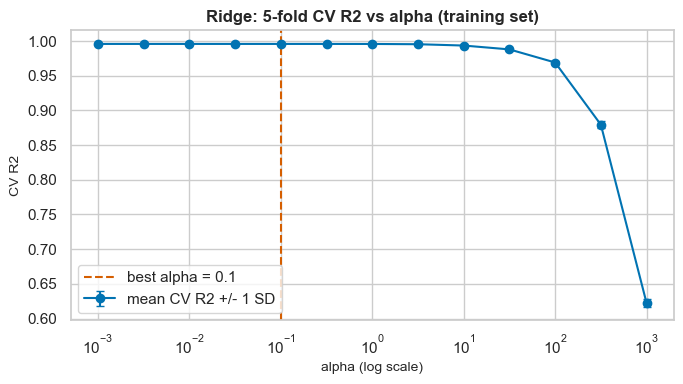

In [20]:
r = train("Ridge Regression")
res = pd.DataFrame(r["search"].cv_results_)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(res["param_model__alpha"].astype(float), res["mean_test_score"], yerr=res["std_test_score"], marker="o", capsize=3, label="mean CV R2 +/- 1 SD")
ax.axvline(r["best_params"]["alpha"], color=sns.color_palette()[3], linestyle="--", label=f"best alpha = {r['best_params']['alpha']:.3g}")
ax.set(xscale="log", title="Ridge: 5-fold CV R2 vs alpha (training set)", xlabel="alpha (log scale)", ylabel="CV R2")
ax.legend(); fig.tight_layout(); save_fig(fig, TRACK, "ridge_alpha_curve"); plt.show()

### 11.3 Lasso Regression — L1 penalty, tune `alpha`, observe sparsity

In [21]:
r = train("Lasso Regression")
sparsity = []
for a in specs["Lasso Regression"].param_grid["model__alpha"]:
    m = make_regression_pipeline(Lasso(alpha=a, max_iter=50_000, random_state=RANDOM_STATE)).fit(X_train, y_train)
    sparsity.append({"alpha": a, "zero coefficients": int((m.named_steps["model"].coef_ == 0).sum()),
                     "of": len(feature_names)})
sparsity = pd.DataFrame(sparsity).merge(cv_table(r, top=20)[["alpha", "mean_test_score"]], on="alpha")
display(sparsity.rename(columns={"mean_test_score": "CV R2"}).round(5))
lasso_coefs = pd.Series(r["final_model"].named_steps["model"].coef_, index=feature_names)
print("Features zeroed at the selected alpha:", list(lasso_coefs[lasso_coefs == 0].index))

Best parameters (5-fold CV on train): {'alpha': 0.0003} | best CV R2 = 0.99586


,R2,RMSE,MAE
baseline (test),-0.00686,0.55056,0.45660
tuned (test),0.99579,0.03560,0.02630
final model (train),0.99610,0.03362,0.02458


,alpha,zero coefficients,of,CV R2
0,0.00001,0,24,0.99583
1,0.00010,4,24,0.99586
2,0.00030,8,24,0.99586
3,0.00100,16,24,0.99557
4,0.00300,18,24,0.99280
5,0.01000,20,24,0.98436
6,0.03000,20,24,0.97355
7,0.10000,21,24,0.88074


Features zeroed at the selected alpha: ['num__tree_age_years', 'cat__variety_Cavendish', 'cat__variety_Fehi', 'cat__variety_Manzano', 'cat__variety_Red Dacca', 'cat__region_Costa Rica', 'cat__region_Ecuador', 'cat__region_Philippines']


### Observation — Lasso sparsity
As `alpha` grows, the L1 penalty drives more coefficients exactly to zero (see the table), and CV R² falls once it starts removing real signal. The CV-selected alpha is small, because there is little collinearity to punish (§6.4). The coefficients it zeroes are the near-useless dummies and growing-condition features, while the ripeness, sugar, firmness and length terms survive at every useful alpha.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 11.4 ElasticNet — combined L1 + L2, tune `alpha` and `l1_ratio`

Best parameters (5-fold CV on train): {'alpha': 0.0001, 'l1_ratio': 0.9} | best CV R2 = 0.99585


,R2,RMSE,MAE
baseline (test),-0.00686,0.55056,0.45660
tuned (test),0.99586,0.03528,0.02611
final model (train),0.99615,0.03338,0.02435


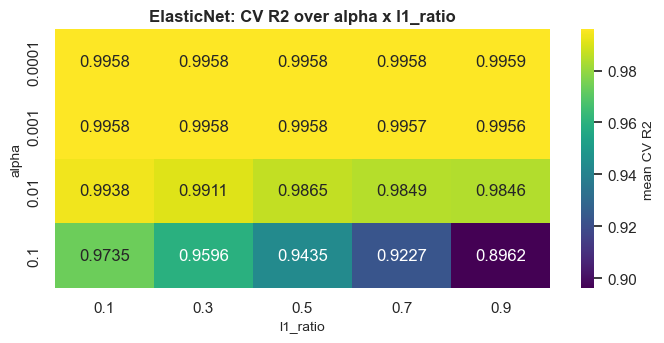

In [22]:
r = train("ElasticNet Regression")
grid = pd.DataFrame(r["search"].cv_results_).pivot_table(index="param_model__alpha", columns="param_model__l1_ratio", values="mean_test_score")
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(grid, annot=True, fmt=".4f", cmap="viridis", cbar_kws={"label": "mean CV R2"}, ax=ax)
ax.set(title="ElasticNet: CV R2 over alpha x l1_ratio", xlabel="l1_ratio", ylabel="alpha")
fig.tight_layout(); save_fig(fig, TRACK, "elasticnet_grid"); plt.show()

### 11.5 Polynomial Regression — `PolynomialFeatures` + `LinearRegression`, compare degrees

The expansion is applied to the **numeric block only** (dummies are not multiplied together), and degrees are capped at 3 to keep the feature count controlled relative to the 800 training rows.

In [23]:
r = train("Polynomial Regression")
deg = cv_table(r, top=3).rename(columns={"mean_test_score": "CV R2", "std_test_score": "CV std"})
deg["design-matrix columns"] = [
    make_regression_pipeline(LinearRegression(), poly_degree=int(d)).fit(X_train, y_train)[:-1]
    .transform(X_train.head(2)).shape[1] for d in deg["degree"]]
display(deg.sort_values("degree").round(5))

Best parameters (5-fold CV on train): {'degree': 3} | best CV R2 = 0.99829


,R2,RMSE,MAE
baseline (test),0.99791,0.02511,0.01911
tuned (test),0.99866,0.02005,0.01512
final model (train),0.99950,0.01199,0.00932


,degree,CV R2,CV std,design-matrix columns
0,1,0.99582,0.00044,24
1,2,0.99765,0.00037,79
2,3,0.99829,0.00035,299


### Observation — polynomial degree
CV R² rises with degree: 0.99582 (degree 1, 24 columns), then 0.99765 (degree 2, 79 columns), then 0.99829 (degree 3, 299 columns). The fold-to-fold standard deviation stays near 0.0004. Degree 3 is selected, but it uses 299 columns for 800 training rows, so over-fitting has to be checked: its train R² (0.9995) is only slightly above its test R² (0.99866), so the extra terms do capture real curvature and interactions rather than noise. The guard against runaway expansion is the cap at degree 3 and the restriction to the numeric block.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 11.6 Decision Tree Regressor — tune `max_depth`, feature importance

Best parameters (5-fold CV on train): {'max_depth': 12, 'min_samples_leaf': 5} | best CV R2 = 0.90851


,R2,RMSE,MAE
baseline (test),0.89260,0.17981,0.14070
tuned (test),0.89498,0.17781,0.14539
final model (train),0.97637,0.08274,0.06421


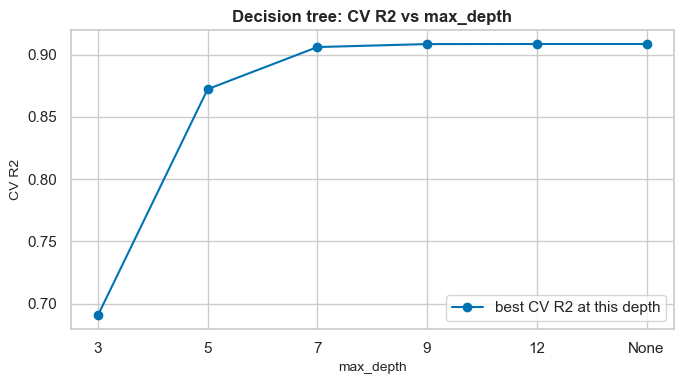

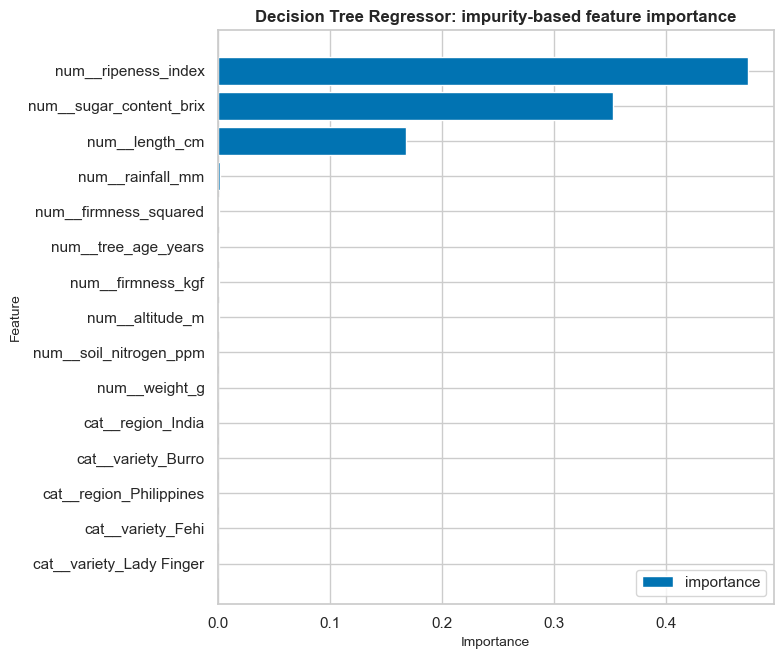

In [24]:
r = train("Decision Tree Regressor")
res = pd.DataFrame(r["search"].cv_results_)
res["max_depth"] = res["param_model__max_depth"].astype(str)
best_per_depth = res.groupby("max_depth")["mean_test_score"].max().reindex(["3", "5", "7", "9", "12", "None"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(best_per_depth.index, best_per_depth.values, marker="o", label="best CV R2 at this depth")
ax.set(title="Decision tree: CV R2 vs max_depth", xlabel="max_depth", ylabel="CV R2"); ax.legend()
fig.tight_layout(); save_fig(fig, TRACK, "tree_depth_curve"); plt.show()
fig = plot_feature_importance(feature_names, r["final_model"].named_steps["model"].feature_importances_,
                              "Decision Tree Regressor: impurity-based feature importance")
save_fig(fig, TRACK, "tree_feature_importance"); plt.show()

### 11.7 Random Forest Regressor — tune `n_estimators` (RandomizedSearchCV)

Best parameters (5-fold CV on train): {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 20} | best CV R2 = 0.96143


,R2,RMSE,MAE
baseline (test),0.95682,0.11401,0.09238
tuned (test),0.95809,0.11232,0.09128
final model (train),0.99521,0.03727,0.02930


,n_estimators,min_samples_leaf,max_features,max_depth,mean_test_score,std_test_score
18,200,1,1.0,20,0.96143,0.00594
5,200,1,1.0,10,0.96110,0.00585
8,200,2,1.0,None,0.96104,0.00588
1,100,1,1.0,None,0.96101,0.00581
3,200,2,1.0,10,0.96096,0.00574
0,100,2,1.0,10,0.96044,0.00563


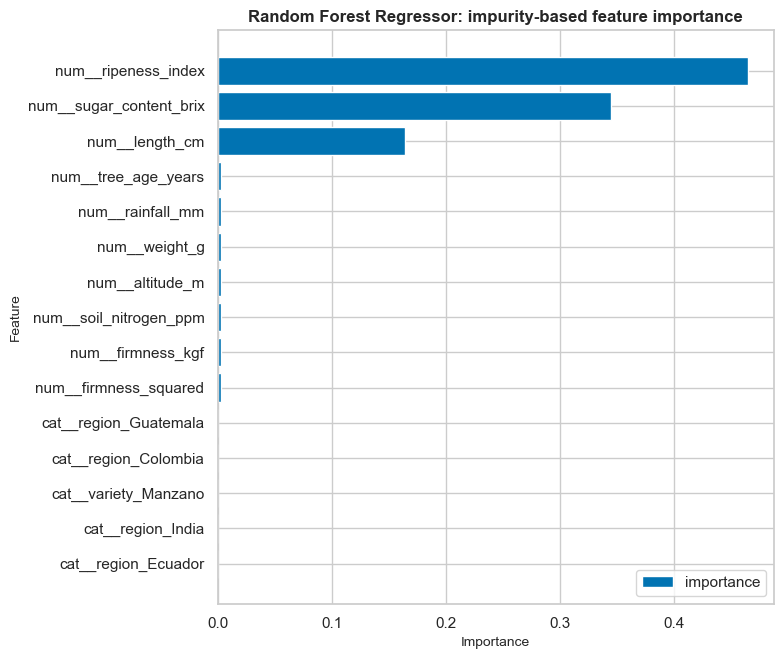

In [25]:
r = train("Random Forest Regressor")
display(cv_table(r, top=6).round(5))
fig = plot_feature_importance(feature_names, r["final_model"].named_steps["model"].feature_importances_,
                              "Random Forest Regressor: impurity-based feature importance")
save_fig(fig, TRACK, "random_forest_feature_importance"); plt.show()

### 11.8 Gradient Boosting Regressor — tune `learning_rate` (RandomizedSearchCV)

Best parameters (5-fold CV on train): {'subsample': 0.8, 'n_estimators': 500, 'max_depth': 2, 'learning_rate': 0.05} | best CV R2 = 0.99275


,R2,RMSE,MAE
baseline (test),0.98764,0.06101,0.04862
tuned (test),0.99358,0.04395,0.03464
final model (train),0.99810,0.02348,0.01865


,subsample,n_estimators,max_depth,learning_rate,mean_test_score,std_test_score
15,0.8,500,2,0.05,0.99275,0.00077
20,1.0,500,2,0.20,0.99117,0.00198
19,1.0,300,2,0.10,0.99089,0.00140
0,0.8,500,2,0.03,0.99065,0.00143
6,0.8,500,3,0.03,0.99053,0.00213
4,0.8,500,3,0.05,0.99028,0.00100


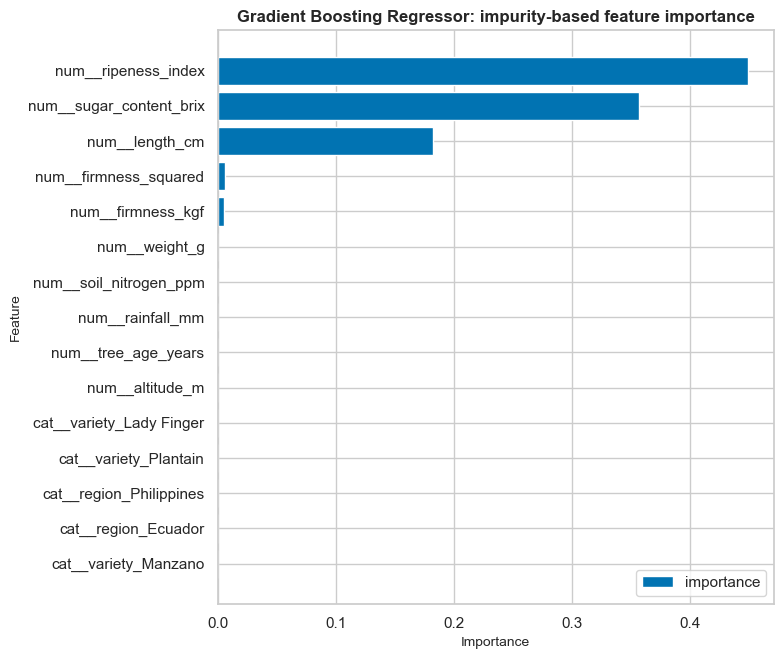

In [26]:
r = train("Gradient Boosting Regressor")
display(cv_table(r, top=6).round(5))
fig = plot_feature_importance(feature_names, r["final_model"].named_steps["model"].feature_importances_,
                              "Gradient Boosting Regressor: impurity-based feature importance")
save_fig(fig, TRACK, "gradient_boosting_feature_importance"); plt.show()

### Observation — tree-based models
All three tree models rank the same handful of features at the top (ripeness, sugar, firmness and its square, length) and give almost no importance to the dummies and growing-condition features. This agrees with the correlation analysis and the linear coefficients. Trees approximate smooth relationships with step functions, so on a target that is close to a smooth function of a few inputs they are expected to trail the linear-family models.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 11.9 Support Vector Regressor — features scaled, tune `C`, `kernel` (and `epsilon`)

In [27]:
r = train("Support Vector Regressor")
res = pd.DataFrame(r["search"].cv_results_)
display(res.pivot_table(index="param_model__C", columns="param_model__kernel", values="mean_test_score", aggfunc="max").round(5))

Best parameters (5-fold CV on train): {'C': 0.1, 'epsilon': 0.01, 'kernel': 'linear'} | best CV R2 = 0.99542


,R2,RMSE,MAE
baseline (test),0.96291,0.10567,0.07531
tuned (test),0.99561,0.03636,0.02366
final model (train),0.99568,0.03536,0.02234


param_model__kernel,linear,rbf
param_model__C,,
0.1,0.99542,0.95022
1.0,0.99540,0.97708
10.0,0.99540,0.97734
100.0,0.99540,0.97734


### 11.10 K-Nearest Neighbors Regressor — tune `k`, and the effect of scaling

Best parameters (5-fold CV on train): {'n_neighbors': 7, 'p': 2, 'weights': 'distance'} | best CV R2 = 0.83488


,R2,RMSE,MAE
baseline (test),0.82720,0.22808,0.18576
tuned (test),0.83288,0.22430,0.18389
final model (train),1.00000,0.00000,0.00000


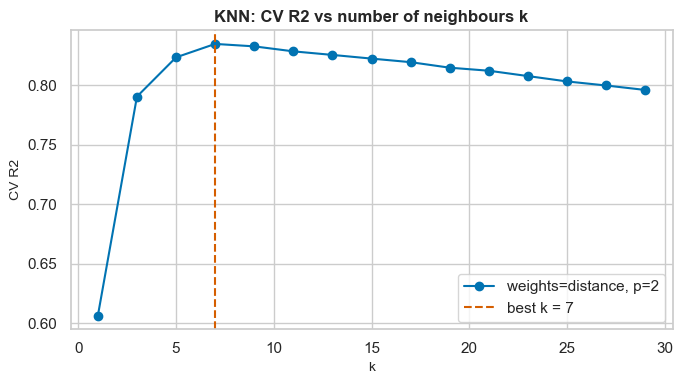

KNN CV R2 with StandardScaler   : 0.8349


KNN CV R2 WITHOUT scaling      : -0.1997


In [28]:
r = train("K-Nearest Neighbors Regressor")
res = pd.DataFrame(r["search"].cv_results_)
best_w, best_p = r["best_params"]["weights"], r["best_params"]["p"]
curve = res[(res["param_model__weights"] == best_w) & (res["param_model__p"] == best_p)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve["param_model__n_neighbors"].astype(int), curve["mean_test_score"], marker="o", label=f"weights={best_w}, p={best_p}")
ax.axvline(r["best_params"]["n_neighbors"], color=sns.color_palette()[3], linestyle="--", label=f"best k = {r['best_params']['n_neighbors']}")
ax.set(title="KNN: CV R2 vs number of neighbours k", xlabel="k", ylabel="CV R2"); ax.legend()
fig.tight_layout(); save_fig(fig, TRACK, "knn_k_curve"); plt.show()

# Same KNN, but numeric features left UNSCALED (only the one-hot step is kept)
unscaled = Pipeline([("pre", ColumnTransformer([("num", "passthrough", config.REG_NUMERIC),
                                               ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), config.REG_CATEGORICAL)])),
                     ("model", r["final_model"].named_steps["model"].__class__(**r["final_model"].named_steps["model"].get_params()))])
print(f"KNN CV R2 with StandardScaler   : {r['best_cv_score']:.4f}")
print(f"KNN CV R2 WITHOUT scaling      : {cross_val_score(unscaled, X_train, y_train, cv=kfold(), scoring='r2').mean():.4f}")

### Observation — why KNN needs scaling
KNN predicts from the average of the nearest training rows under Euclidean (p = 2) or Manhattan (p = 1) distance. Without scaling, distance is dominated by `rainfall_mm` and `altitude_m` (standard deviations in the hundreds), which §6.4 showed are unrelated to quality, so the "nearest" neighbours are effectively random. The scaled vs unscaled CV scores above measure how large that effect is.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 12. Consolidated comparison table (C2)

All ten tuned models scored on the **same 200-row test set**, ranked by test R². Training R² and the best 5-fold CV R² are shown alongside so that over-fitting is visible (a train score far above the CV and test scores is the warning sign). Times are measured on this machine and are only indicative.

,Model,Test R2,Test RMSE,Test MAE,Train R2,"CV R2 (5-fold, train)",Baseline test R2,Fit time (s),Latency (ms / 1k rows),Size (MB)
Rank,,,,,,,,,,
1,Polynomial Regression,0.99866,0.02005,0.01512,0.99950,0.99829,0.99791,0.02424,18.8295,0.01471
2,Linear Regression,0.99589,0.03519,0.02605,0.99616,NaN,0.99589,0.00934,15.5085,0.00395
3,Ridge Regression,0.99588,0.03522,0.02609,0.99616,0.99582,0.99578,0.01416,16.5800,0.00380
4,ElasticNet Regression,0.99586,0.03528,0.02611,0.99615,0.99585,-0.00686,0.01086,18.6170,0.00388
5,Lasso Regression,0.99579,0.03560,0.02630,0.99610,0.99586,-0.00686,0.01152,16.8100,0.00387
6,Support Vector Regressor,0.99561,0.03636,0.02366,0.99568,0.99542,0.96291,0.06545,23.4125,0.09796
7,Gradient Boosting Regressor,0.99358,0.04395,0.03464,0.99810,0.99275,0.98764,0.74564,17.7965,0.40831
8,Random Forest Regressor,0.95809,0.11232,0.09128,0.99521,0.96143,0.95682,0.24297,159.2130,13.04879
9,Decision Tree Regressor,0.89498,0.17781,0.14539,0.97637,0.90851,0.89260,0.01198,13.3690,0.02182


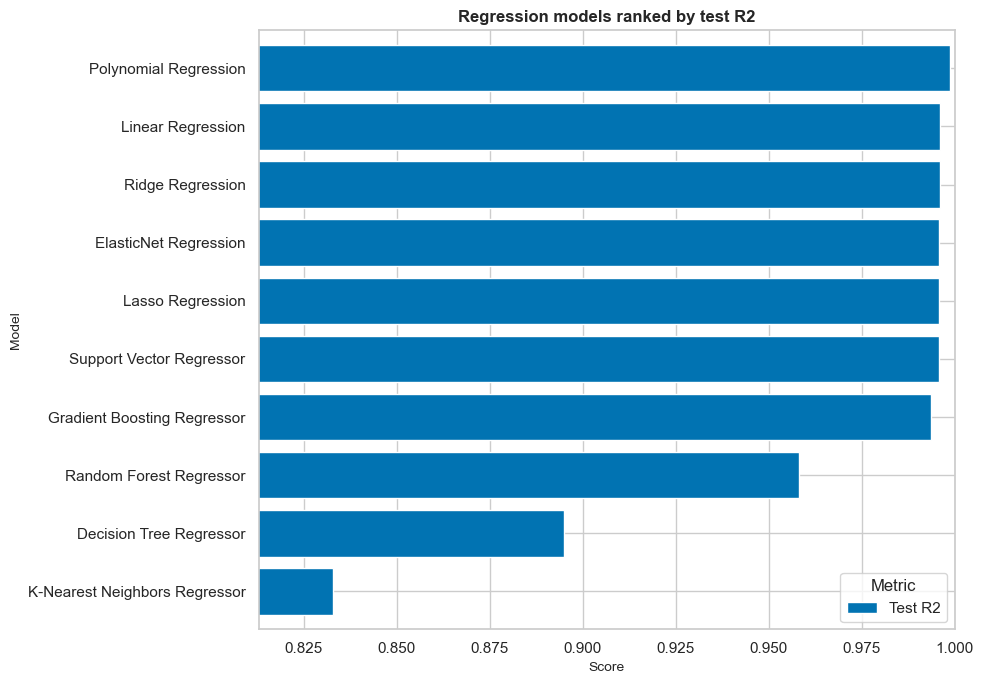

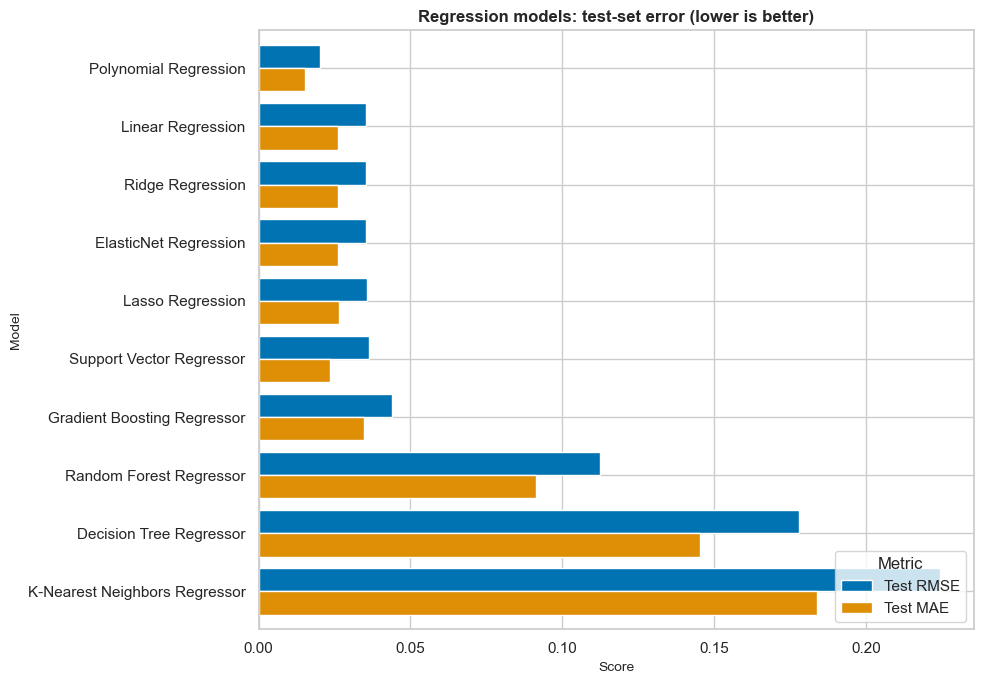

In [29]:
rows = []
for name, r in runs.items():
    rows.append({
        "Model": name,
        "Test R2": r["final_test"]["R2"], "Test RMSE": r["final_test"]["RMSE"], "Test MAE": r["final_test"]["MAE"],
        "Train R2": r["final_train"]["R2"],
        "CV R2 (5-fold, train)": r.get("best_cv_score", np.nan),
        "Baseline test R2": r["baseline_test"]["R2"],
        "Best params": r.get("best_params", "n/a (no hyperparameters)"),
        "Fit time (s)": r["final_fit_seconds"], "Latency (ms / 1k rows)": r["latency_ms_per_1k"], "Size (MB)": r["size_mb"],
    })
comparison = pd.DataFrame(rows).sort_values("Test R2", ascending=False).reset_index(drop=True)
comparison.index = comparison.index + 1
comparison.index.name = "Rank"
comparison.to_csv(config.RESULTS_DIR / "regression_results.csv")
display(comparison.drop(columns=["Best params"]).round(5))

fig = plot_metric_bars(comparison.reset_index(), ["Test R2"], "Regression models ranked by test R2", xlim=(comparison["Test R2"].min() - 0.02, 1.0))
save_fig(fig, TRACK, "model_comparison_r2"); plt.show()
fig = plot_metric_bars(comparison.reset_index(), ["Test RMSE", "Test MAE"], "Regression models: test-set error (lower is better)")
save_fig(fig, TRACK, "model_comparison_errors"); plt.show()

### Observation — comparison
- **Polynomial Regression (degree 3) ranks first**, with test R² = 0.99866, RMSE = 0.0201 and MAE = 0.0151.
- Linear, Ridge, ElasticNet, Lasso and the (linear-kernel) SVR form a tight group at R² 0.9956–0.9959. With uncorrelated features and the `firmness_squared` term already supplied, the regularised variants have almost nothing to correct.
- Gradient Boosting (0.9936) comes next, followed by Random Forest (0.958), Decision Tree (0.895) and KNN (0.833).
- **Over-fitting is visible in the train-vs-test gap.** KNN with distance weighting scores 1.000 on its own training rows but 0.833 on the test set, and the Decision Tree scores 0.976 vs 0.895. The linear-family models have almost identical train and test R² (≈ 0.996), which is the low-variance behaviour expected from a simple model.
- **Cost:** the Random Forest is by far the largest model (about 13 MB in memory, 2.9 MB on disk) and the slowest to predict. The linear models are kilobytes in size.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 13. Hyperparameter tuning summary (C3)

Baseline (defaults) versus tuned configuration on the test set. The tuning decision itself was made from cross-validation on the training set, so a small drop on the test set is possible and is reported honestly.

In [30]:
tuning = []
for name, r in runs.items():
    if r["search"] is None:
        continue
    tuning.append({
        "Model": name, "Search": specs[name].search + " search", "Configs tried": len(r["search"].cv_results_["params"]),
        "Best params": r["best_params"], "Best CV R2": r["best_cv_score"],
        "Baseline test R2": r["baseline_test"]["R2"], "Tuned test R2": r["tuned_test"]["R2"],
        "R2 change": r["tuned_test"]["R2"] - r["baseline_test"]["R2"],
        "RMSE change": r["tuned_test"]["RMSE"] - r["baseline_test"]["RMSE"],
    })
tuning = pd.DataFrame(tuning).sort_values("R2 change", ascending=False).reset_index(drop=True)
display(tuning.round(5))

hp_path = config.RESULTS_DIR / "hyperparameter_results.json"
hp = load_json(hp_path) if hp_path.exists() else {}
hp["regression"] = {row["Model"]: {k: row[k] for k in tuning.columns if k != "Model"} for _, row in tuning.iterrows()}
save_json(hp, hp_path)
print("Saved", hp_path.relative_to(PROJECT_ROOT))

,Model,Search,Configs tried,Best params,Best CV R2,Baseline test R2,Tuned test R2,R2 change,RMSE change
0,ElasticNet Regression,grid search,20,"{'alpha': 0.0001, 'l1_ratio': 0.9}",0.99585,-0.00686,0.99586,1.00273,-0.51527
1,Lasso Regression,grid search,8,{'alpha': 0.0003},0.99586,-0.00686,0.99579,1.00265,-0.51496
2,Support Vector Regressor,grid search,24,"{'C': 0.1, 'epsilon': 0.01, 'kernel': 'linear'}",0.99542,0.96291,0.99561,0.03270,-0.06930
3,Gradient Boosting Regressor,random search,25,"{'subsample': 0.8, 'n_estimators': 500, 'max_depth': 2, 'learning_rate': 0.05}",0.99275,0.98764,0.99358,0.00595,-0.01706
4,K-Nearest Neighbors Regressor,grid search,60,"{'n_neighbors': 7, 'p': 2, 'weights': 'distance'}",0.83488,0.82720,0.83288,0.00568,-0.00378
5,Decision Tree Regressor,grid search,24,"{'max_depth': 12, 'min_samples_leaf': 5}",0.90851,0.89260,0.89498,0.00238,-0.00200
6,Random Forest Regressor,random search,20,"{'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth...",0.96143,0.95682,0.95809,0.00127,-0.00169
7,Polynomial Regression,grid search,3,{'degree': 3},0.99829,0.99791,0.99866,0.00076,-0.00506
8,Ridge Regression,grid search,13,{'alpha': 0.1},0.99582,0.99578,0.99588,0.00010,-0.00041


Saved reports\results\hyperparameter_results.json


### Observation — tuning
- Tuning raised test R² for **all nine** tunable models. The gains range from +0.0001 (Ridge) to about +1.0 (Lasso and ElasticNet).
- The huge Lasso/ElasticNet jump is not a modelling breakthrough. The library default `alpha = 1.0` is so strong, relative to a target with standard deviation 0.54, that it sets every coefficient to zero and the model predicts the training mean (R² ≈ −0.007). Cross-validation selects alpha = 0.0003 / 0.0001 instead.
- SVR improved from 0.963 (default RBF kernel) to 0.9956 when the search chose a **linear** kernel. That is further evidence that the relationship is close to linear once `firmness_squared` is included.
- Gradient Boosting improved (0.9876 → 0.9936) by using shallower trees (depth 2), more of them (500), a smaller learning rate (0.05) and row subsampling (0.8).

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 14. 5-fold cross-validated R² for the two best models

The two models with the highest test R² are re-evaluated with **5-fold CV on the training set**. Each fold refits the whole pipeline (feature engineering, imputer, encoder, scaler, model) on four-fifths of the training rows and scores the remaining fifth. The test set is not used here.

*Caveat:* each model's hyperparameters were chosen with the same folds, so these CV means are slightly optimistic. The untouched test score in §12 is the unbiased check.

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,test R2
Polynomial Regression,0.99889,0.99827,0.99781,0.99824,0.99822,0.99829,0.00035,0.99866
Linear Regression,0.99644,0.99610,0.99513,0.99570,0.99574,0.99582,0.00044,0.99589


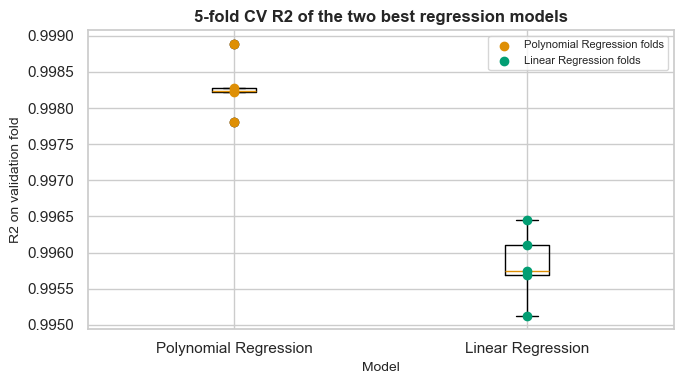

In [31]:
top_two = comparison["Model"].head(2).tolist()
cv_results = {name: cross_validate(runs[name]["final_model"], X_train, y_train, kfold(), "r2") for name in top_two}
cv_table_top = pd.DataFrame({name: {**{f"fold {i + 1}": s for i, s in enumerate(v["scores"])}, "mean": v["mean"], "std": v["std"],
                                    "test R2": runs[name]["final_test"]["R2"]} for name, v in cv_results.items()}).T
display(cv_table_top.round(5))
save_json(cv_results, config.RESULTS_DIR / "regression_cv.json")

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([cv_results[n]["scores"] for n in top_two], tick_labels=top_two)
for i, n in enumerate(top_two, start=1):
    ax.scatter([i] * 5, cv_results[n]["scores"], color=sns.color_palette()[i], zorder=3, label=f"{n} folds")
ax.set(title="5-fold CV R2 of the two best regression models", xlabel="Model", ylabel="R2 on validation fold"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, TRACK, "cv_top2_boxplot"); plt.show()

## 15. Model selection and diagnostics (C4)

**Selection rule (decided before looking at the outcome):** among the two best models by test R², choose the one with the higher **mean 5-fold CV R²**, which is training-only evidence. If the two means differ by less than one CV standard deviation, prefer the model with fewer parameters, because it is easier to explain and less likely to over-fit.

In [32]:
a, b = top_two
gap = abs(cv_results[a]["mean"] - cv_results[b]["mean"])
if gap < max(cv_results[a]["std"], cv_results[b]["std"]):
    n_params = {n: runs[n]["final_model"][:-1].transform(X_train.head(1)).shape[1] for n in top_two}
    selected = min(top_two, key=lambda n: (n_params[n], -cv_results[n]["mean"]))
    reason = f"CV means differ by {gap:.5f} (< 1 SD), so the simpler model ({n_params[selected]} input columns) is preferred"
else:
    selected = max(top_two, key=lambda n: cv_results[n]["mean"])
    reason = f"higher mean CV R2 ({cv_results[selected]['mean']:.5f}) by {gap:.5f}, more than one SD"
best = runs[selected]["final_model"]
print(f"Selected model: {selected} -> {reason}")
print("Test metrics:", {k: round(v, 5) for k, v in runs[selected]["final_test"].items()})

Selected model: Polynomial Regression -> higher mean CV R2 (0.99829) by 0.00247, more than one SD
Test metrics: {'R2': 0.99866, 'RMSE': 0.02005, 'MAE': 0.01512}


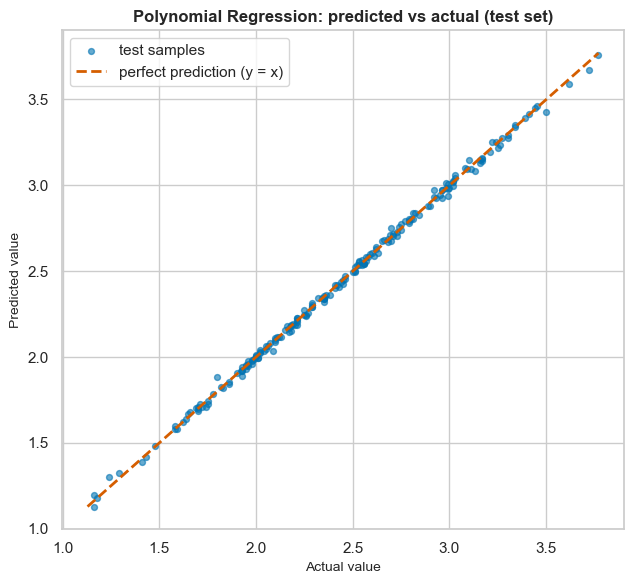

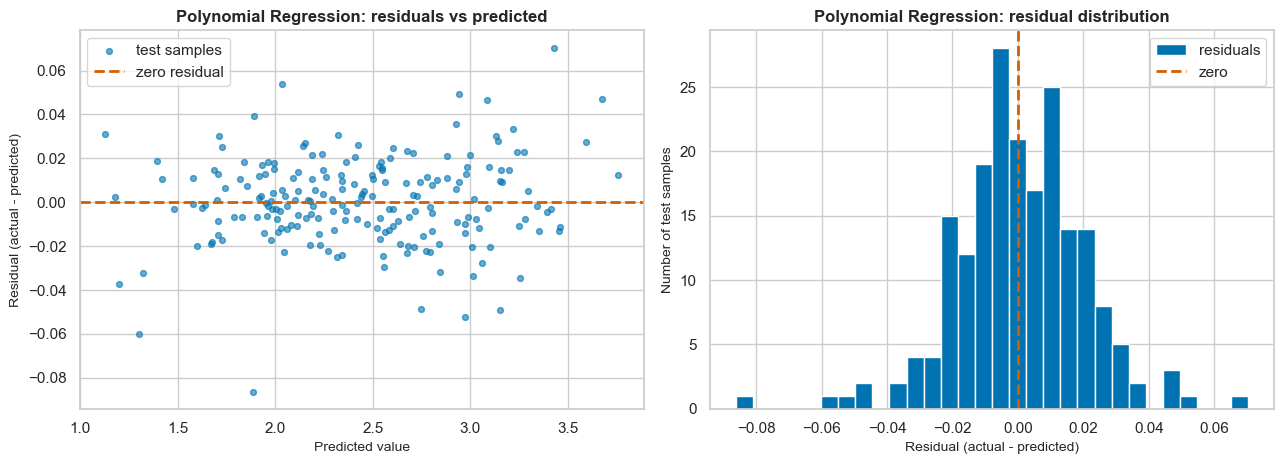

Residual mean = +0.00053, std = 0.02009, max |residual| = 0.0863


In [33]:
pred = best.predict(X_test)
fig = plot_predicted_vs_actual(y_test, pred, f"{selected}: predicted vs actual (test set)")
save_fig(fig, TRACK, "best_model_predicted_vs_actual"); plt.show()
fig = plot_residuals(y_test, pred, selected)
save_fig(fig, TRACK, "best_model_residuals"); plt.show()
res = y_test - pred
print(f"Residual mean = {res.mean():+.5f}, std = {res.std():.5f}, max |residual| = {res.abs().max():.4f}")

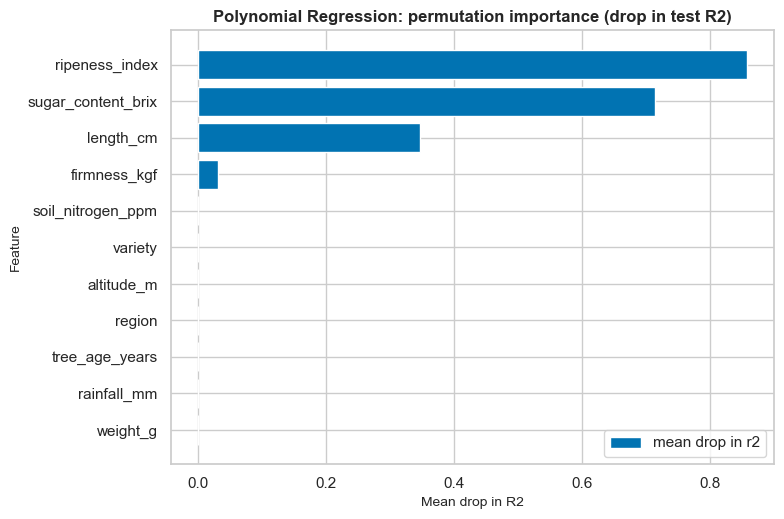

In [34]:
# Model-agnostic check: permutation importance of the RAW input columns for the selected pipeline (test set).
perm = permutation_importance(best, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="r2")
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = plot_feature_importance(perm_s.index, perm_s.values, f"{selected}: permutation importance (drop in test R2)", xlabel="Mean drop in R2")
save_fig(fig, TRACK, "best_model_permutation_importance"); plt.show()

### Observation — diagnostics
- Predicted vs actual points lie tightly along y = x across the whole range, including the few `Unripe` (< 1.5) and `Premium` (> 3.5) samples.
- Residuals are centred on zero (mean +0.0005, SD 0.020, largest |residual| 0.086) and show no funnel shape or curvature against the predicted value, so there is no sign of a remaining systematic pattern.
- Permutation importance on the raw inputs agrees with the EDA. Shuffling `ripeness_index` lowers test R² by about 0.86, `sugar_content_brix` by about 0.71 and `length_cm` by about 0.35. `firmness_kgf` matters less (about 0.03), consistent with its modest +0.013 CV gain in §9. Shuffling variety, region or any growing-condition feature changes R² by almost nothing.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 16. Saving the model pipelines

Every tuned pipeline is saved with `joblib` to `models/regression/`, together with a JSON metadata file. Each file contains the **complete** pipeline (feature engineering → imputer → encoder → scaler → model), so the app can pass raw inputs and get exactly the training-time preprocessing. `selection.json` records which model was selected and why, and `feature_schema.json` records the training-set input ranges and categories that the app uses for validation.

In [35]:
for name, r in runs.items():
    save_pipeline(r["final_model"], TRACK, name, {
        "task": "regression", "target": config.REG_TARGET, "selected": name == selected,
        "test_metrics": r["final_test"], "best_params": r.get("best_params", {}),
        "cv_r2_mean": r.get("best_cv_score"),
    })

schema = {
    "target": config.REG_TARGET,
    "numeric": {c: {"min": float(X_train[c].min()), "max": float(X_train[c].max()),
                    "median": float(X_train[c].median())} for c in config.REG_NUMERIC},
    "categorical": {c: sorted(X_train[c].unique().tolist()) for c in config.REG_CATEGORICAL},
    "examples": [{**row, "actual_" + config.REG_TARGET: float(y_test.loc[idx])}
                 for idx, row in X_test.head(3).to_dict(orient="index").items()],
}
save_json(schema, config.MODELS_DIR / TRACK / "feature_schema.json")
save_json({"selected_model": selected, "file": slugify(selected) + ".joblib", "rule": reason,
           "test_metrics": runs[selected]["final_test"], "cv": cv_results[selected],
           "ranking_metric": "test R2 (rubric C2); selection by mean 5-fold CV R2 among the top two"},
          config.MODELS_DIR / TRACK / "selection.json")

# Round-trip check: the reloaded pipeline must reproduce the in-memory predictions exactly.
reloaded = load_pipeline(config.MODELS_DIR / TRACK / (slugify(selected) + ".joblib"))
assert np.allclose(reloaded.predict(X_test), pred), "reloaded model gives different predictions"
for f in sorted((config.MODELS_DIR / TRACK).glob("*.joblib")):
    print(f"{f.name:45s} {f.stat().st_size / 1024:8.1f} KB")
print("Reload check passed: identical predictions from", slugify(selected) + ".joblib")

decision_tree_regressor.joblib                     8.6 KB
elasticnet_regression.joblib                       2.5 KB
gradient_boosting_regressor.joblib               102.9 KB
k_nearest_neighbors_regressor.joblib              64.5 KB
lasso_regression.joblib                            2.5 KB
linear_regression.joblib                           2.7 KB
polynomial_regression.joblib                      13.3 KB
random_forest_regressor.joblib                  2968.9 KB
ridge_regression.joblib                            2.5 KB
support_vector_regressor.joblib                   40.8 KB
Reload check passed: identical predictions from polynomial_regression.joblib


## 17. Limitations
- **The data appears synthetic.** Uniform features with round-number bounds and R² close to 1 are not what real agricultural measurements look like. The results show that the pipeline is correct, not that banana quality can be predicted this well in practice.
- **A near-perfect ceiling compresses the comparison.** When most models exceed R² = 0.98, differences between the leaders are small relative to sampling noise on a 200-row test set. That is why CV is reported as well.
- **One harvest season (Sept–Oct 2023)**, so nothing here supports conclusions across seasons or years.
- **The relationships are associations, not causes.**
- Hyperparameters were tuned on the same folds used for the top-two CV scores, so those CV means are slightly optimistic.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 18. Conclusion
- All ten required algorithms were trained on one leakage-safe pipeline and scored on the same 200-row test set. Nine were tuned with grid or randomised search using 5-fold CV on the training data.
- The **selected model is Polynomial Regression (degree 3)**, chosen by mean 5-fold CV R² (0.99829 ± 0.00035) over the runner-up Linear Regression (0.99582 ± 0.00044). Its held-out test score is R² = 0.99866, RMSE = 0.0201, MAE = 0.0151.
- Quality in this dataset is explained almost entirely by four properties of the fruit itself: ripeness, sugar content, length, and firmness through a non-linear (squared) term. Variety, region and the growing-condition features add essentially nothing.
- The near-perfect scores most likely reflect a synthetic data-generating process. The transferable lessons are the methodology: the leakage audit, training-only feature engineering, and selection by cross-validation.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

---
**References.** scikit-learn user guide (pipelines, model selection, linear models, ensembles), https://scikit-learn.org/stable/user_guide.html. No code was copied from other external sources. AI assistance is disclosed at the top of this notebook and in the README.